# QR decomposition: build an orthogonal basis

The QR decomposition factors a matrix into an orthogonal (or unitary) matrix `Q` and an upper-triangular matrix `R`:

$$A = QR, \qquad Q^\mathsf{T}Q = I.$$

The columns of `Q` form an orthonormal basis for the column space of `A`; `R` records how to combine that basis to recover the original columns. We will connect QR to Gram–Schmidt, see how column pivoting chooses useful image columns, and compare low-rank approximations with the optimal truncated SVD.

## 1. Gram–Schmidt creates an orthogonal basis

Given independent columns `a₁, a₂, …`, Gram–Schmidt subtracts from each column its projections onto the previously found basis vectors, then normalizes the remainder. The result is a set of orthonormal columns in `Q`; the projection coefficients fill the upper-triangular matrix `R`.

In [1]:
using LinearAlgebra
using Images
using ImageIO

function modified_gram_schmidt(A)
    m, n = size(A)
    Q = zeros(Float64, m, n)
    R = zeros(Float64, n, n)

    for j in 1:n
        v = Float64.(A[:, j])
        for i in 1:j-1
            R[i, j] = dot(Q[:, i], v)
            v .-= R[i, j] .* Q[:, i]
        end
        R[j, j] = norm(v)
        iszero(R[j, j]) && throw(ArgumentError("columns must be linearly independent"))
        Q[:, j] = v ./ R[j, j]
    end

    Q, R
end

A_demo = [1.0 1 1;
          1 0 2;
          0 1 1;
          1 2 0]
Q_demo, R_demo = modified_gram_schmidt(A_demo)
(Q_demo, R_demo, norm(Q_demo' * Q_demo - I), norm(A_demo - Q_demo * R_demo))

([0.5773502691896258 -1.2819751242557095e-16 -1.812986607347358e-16; 0.5773502691896258 -0.577350269189626 0.4082482904638628; 0.0 0.5773502691896258 0.8164965809277261; 0.5773502691896258 0.5773502691896256 -0.4082482904638632], [1.7320508075688772 1.7320508075688776 1.7320508075688776; 0.0 1.7320508075688772 -0.5773502691896257; 0.0 0.0 1.632993161855452], 7.238919952966046e-16, 2.5349828230834066e-16)

The last two values should be close to zero: the columns of `Q` are orthonormal, and `QR` reconstructs `A`. This implementation uses **modified Gram–Schmidt**, which updates the remainder after each projection and is more numerically stable than classical Gram–Schmidt. For demanding numerical work, Julia's `qr` uses Householder reflectors, a robust standard approach.

In [2]:
householder = qr(A_demo)
Q_householder = Matrix(householder.Q)
R_householder = Matrix(householder.R)
(norm(Q_householder' * Q_householder - I), norm(A_demo - Q_householder * R_householder))

(2.0510049743231618e-16, 4.173406244615327e-16)

## 2. Show the original image

Before deriving a matrix from the image, display the original in color. We will use a smaller grayscale copy for the QR comparisons so the factorizations run quickly.

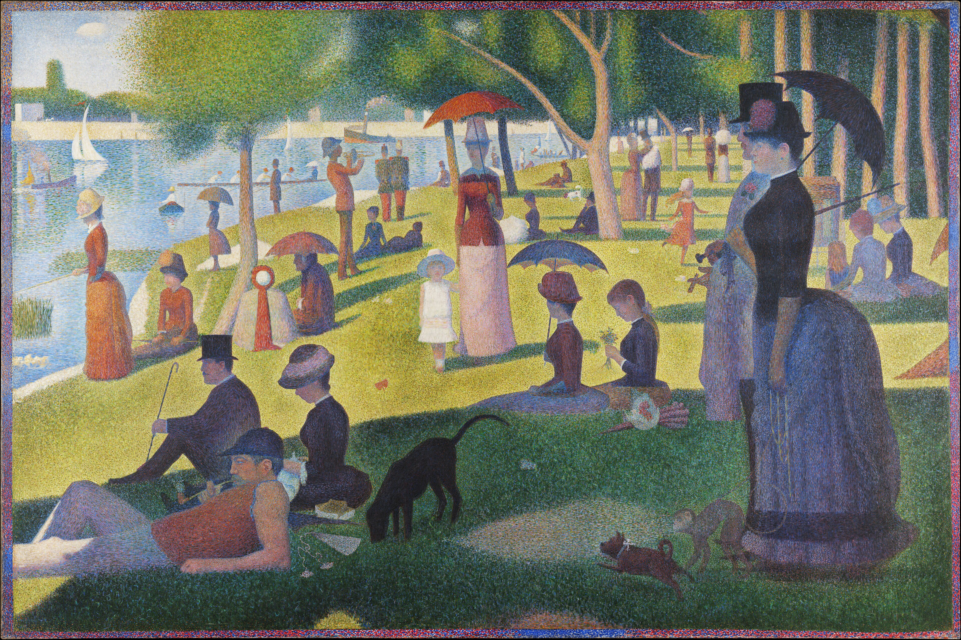

In [3]:
image_path = joinpath(@__DIR__, "..", "images", "sunday-la-grande-jatte.jpg")
original = load(image_path)
original

In [4]:
image_matrix = Float64.(Gray.(original[1:4:end, 1:4:end]))
(size(image_matrix), extrema(image_matrix))

((639, 960), (0.0, 0.996078431372549))

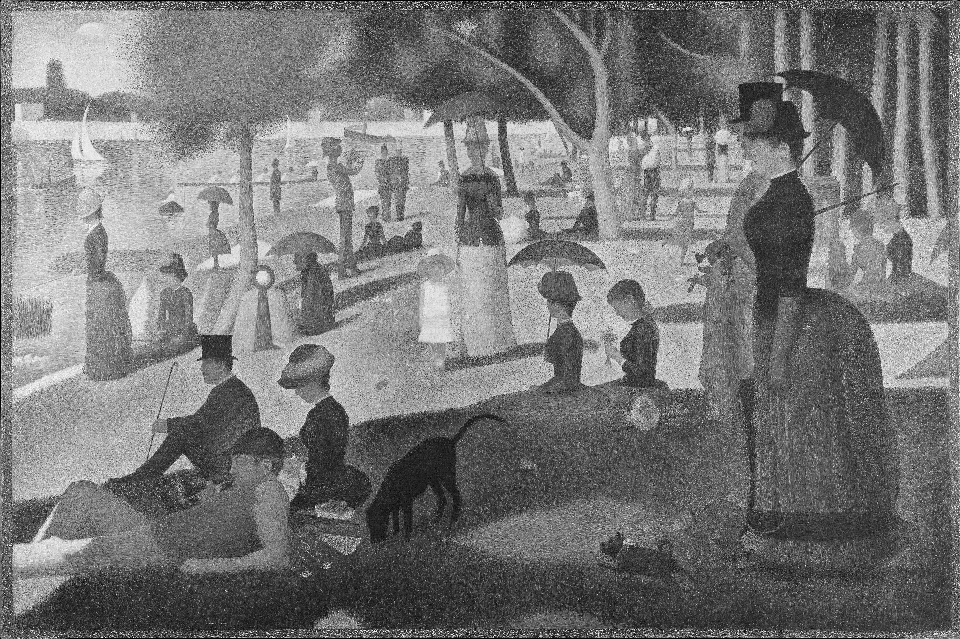

In [5]:
Gray.(image_matrix)

Each column of `image_matrix` is one vertical slice of pixels. Approximating its column space with a small number of orthonormal vectors gives a low-rank image approximation. The next comparison uses the same rank for all three strategies.

## 3. Compare three rank-`k` approximations

A plain QR factorization starts with the image columns in their original order. Column-pivoted QR reorders the columns to select representative image slices early; Julia's `ColumnNorm()` strategy chooses pivots using residual column norms. For either factorization, projecting the whole image onto the first `k` columns of `Q` gives a rank-at-most-`k` approximation.

The truncated SVD is included as a benchmark: by the Eckart–Young theorem, it has the smallest possible Frobenius error among all rank-`k` approximations. Pivoted QR is a useful basis-selection heuristic, but is not guaranteed to beat plain QR for every image.

In [6]:
k = 30
max_rank = min(size(image_matrix)...)
1 <= k <= max_rank || throw(ArgumentError("k must be between 1 and $max_rank"))

qr_plain = qr(image_matrix)
Q_plain = Matrix(qr_plain.Q)[:, 1:k]
plain_approximation = Q_plain * (Q_plain' * image_matrix)

qr_pivoted = qr(image_matrix, ColumnNorm())
Q_pivoted = Matrix(qr_pivoted.Q)[:, 1:k]
pivoted_approximation = Q_pivoted * (Q_pivoted' * image_matrix)
selected_columns = qr_pivoted.p[1:k]

image_svd = svd(image_matrix; full=false)
svd_approximation = image_svd.U[:, 1:k] * Diagonal(image_svd.S[1:k]) * image_svd.Vt[1:k, :]

selected_columns[1:min(k, 10)]

10-element Vector{Int64}:
  38
 439
 960
 650
 327
 914
 808
  11
 114
 956

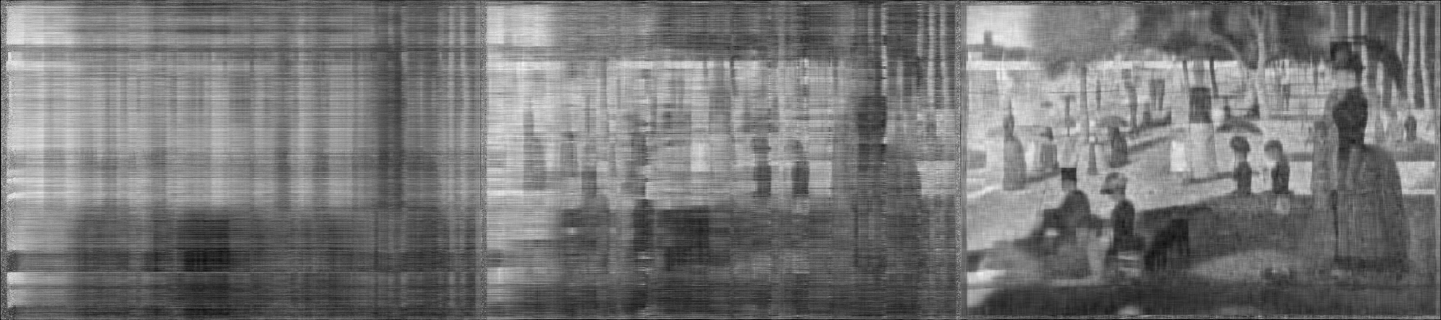

In [7]:
Gray.(clamp.(hcat(plain_approximation, pivoted_approximation, svd_approximation), 0, 1))

The three image panels are arranged left to right: **plain QR**, **column-pivoted QR**, and **truncated SVD**. Pivoting changes which image columns form the basis, not the order of pixels in the final reconstruction. The SVD panel is the best rank-`k` approximation in Frobenius norm; the QR panels show what the selected orthogonal subspaces capture.

In [8]:
relative_error(X) = norm(image_matrix - X) / norm(image_matrix)
[(method="plain QR", relative_error=relative_error(plain_approximation)),
 (method="column-pivoted QR", relative_error=relative_error(pivoted_approximation)),
 (method="truncated SVD", relative_error=relative_error(svd_approximation))]

3-element Vector{@NamedTuple{method::String, relative_error::Float64}}:
 (method = "plain QR", relative_error = 0.3051197957672578)
 (method = "column-pivoted QR", relative_error = 0.25750643766087683)
 (method = "truncated SVD", relative_error = 0.2053683895142458)

All three approximations have rank at most `k`. The truncated SVD error should be no greater than either QR projection's error, apart from tiny floating-point differences. Column pivoting often improves on unpivoted QR, but it is a heuristic rather than an optimal rank-`k` approximation.

## Your turn

1. Change `k` and compare the three panels and their relative errors. How quickly does each basis capture the image?
2. Compare the selected pivot columns with the first `k` image columns. What makes a column useful to the basis?
3. Try a different image from `images/`. Does column pivoting help more on some images than others?
4. Modify the demonstration matrix to have nearly dependent columns. Compare modified Gram–Schmidt with Householder QR by checking `‖QᵀQ - I‖`.

QR is useful for constructing orthogonal bases, solving least-squares problems, and building practical approximations. SVD remains the benchmark when the goal is minimum rank-`k` Frobenius error.